        Date       Close        High         Low        Open    Volume  \
0 2016-01-29  106.949997  107.000000  106.260002  106.610001   8098700   
1 2016-02-01  108.050003  108.150002  107.529999  107.540001  10471800   
2 2016-02-02  108.089996  108.180000  107.349998  107.919998   6656000   
3 2016-02-03  109.250000  109.580002  107.900002  107.910004  15785200   
4 2016-02-04  110.570000  110.699997  109.919998  110.449997  13213700   

    Adj Close  Daily_Return  MA_20  MA_50  MA_200  Volatility_20  Year  Month  \
0  106.949997           NaN    NaN    NaN     NaN            NaN  2016      1   
1  108.050003      1.028524    NaN    NaN     NaN            NaN  2016      2   
2  108.089996      0.037014    NaN    NaN     NaN            NaN  2016      2   
3  109.250000      1.073183    NaN    NaN     NaN            NaN  2016      2   
4  110.570000      1.208238    NaN    NaN     NaN            NaN  2016      2   

   Day_of_Week  Quarter  
0            4        1  
1            0  

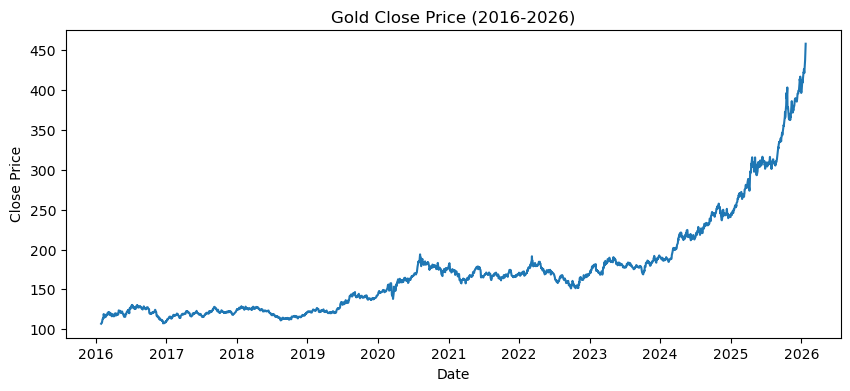


Total, Train, Test: 2490 1992 498

Simple Linear Regression
Coefficient: 0.9989113717823739
Intercept: 0.19591506320085728
Mean Squared Error: 12.861120064701767

Multiple Regression
Coefficients: [ 9.90667702e-01 -1.40662290e-08  7.72512619e-03  2.15641868e-01]
Intercept: 0.22053356288824943
Mean Squared Error: 13.035566203518613

Naive baseline MSE (tomorrow = today): 12.690406535386483

Model Comparison
Simple Regression MSE  : 12.861120064701767
Multiple Regression MSE: 13.035566203518613
Naive Baseline MSE     : 12.690406535386483
Better model: Simple


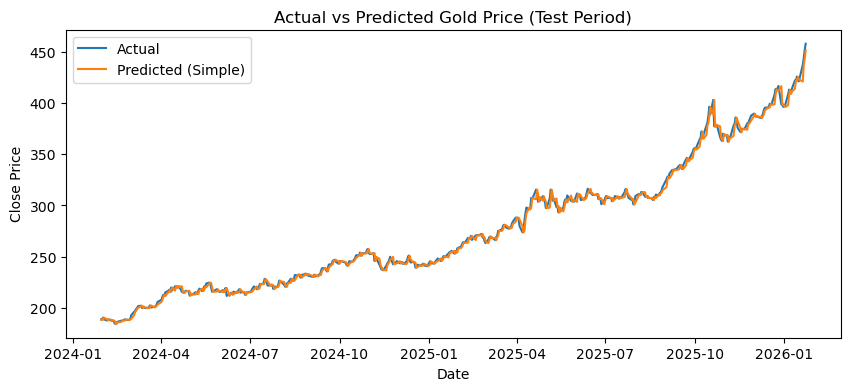

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# ---------- 1. Load and clean ----------
df = pd.read_csv(r"C:\Users\srini\Downloads\gold price.csv")
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date').reset_index(drop=True)
print(df.head())
print("Shape:", df.shape)

# ---------- 2. Univariate analysis ----------
def univariate_analysis(df, column):
    freq = df[column].value_counts()
    mean = df[column].mean()
    median = df[column].median()
    mode = df[column].mode()[0]
    std = df[column].std()
    return freq, mean, median, mode, std

freq, mean, median, mode, std = univariate_analysis(df, 'Close')
print("\nUnivariate Analysis for Close")
print("Frequency (top 5):\n", freq.head())
print("Mean:", mean)
print("Median:", median)
print("Mode:", mode)
print("Standard Deviation:", std)

plt.figure(figsize=(10, 4))
plt.plot(df['Date'], df['Close'])
plt.title("Gold Close Price (2016-2026)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.show()

# ---------- 3. Lag features ----------
df['Close_lag1']  = df['Close'].shift(1)
df['Volume_lag1'] = df['Volume'].shift(1)
df['MA20_lag1']   = df['MA_20'].shift(1)
df['Vol20_lag1']  = df['Volatility_20'].shift(1)

lag_cols = ['Close_lag1', 'Volume_lag1', 'MA20_lag1', 'Vol20_lag1']
data = df.dropna(subset=lag_cols)

# ---------- 4. Chronological split ----------
split = int(len(data) * 0.8)
train = data.iloc[:split]
test  = data.iloc[split:]
print("\nTotal, Train, Test:", len(data), len(train), len(test))

# ---------- 5. Simple linear regression ----------
X_train, y_train = train[['Close_lag1']], train['Close']
X_test,  y_test  = test[['Close_lag1']],  test['Close']

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)
mse_simple = mean_squared_error(y_test, y_pred)

print("\nSimple Linear Regression")
print("Coefficient:", lin_reg.coef_[0])
print("Intercept:", lin_reg.intercept_)
print("Mean Squared Error:", mse_simple)

# ---------- 6. Multiple regression ----------
features = lag_cols

multi_reg = LinearRegression()
multi_reg.fit(train[features], y_train)
y_pred_multi = multi_reg.predict(test[features])
mse_multi = mean_squared_error(y_test, y_pred_multi)

print("\nMultiple Regression")
print("Coefficients:", multi_reg.coef_)
print("Intercept:", multi_reg.intercept_)
print("Mean Squared Error:", mse_multi)

# ---------- 7. Naive baseline ----------
mse_naive = mean_squared_error(y_test, test['Close_lag1'])
print("\nNaive baseline MSE (tomorrow = today):", mse_naive)

# ---------- 8. Comparison ----------
print("\nModel Comparison")
print("Simple Regression MSE  :", mse_simple)
print("Multiple Regression MSE:", mse_multi)
print("Naive Baseline MSE     :", mse_naive)
print("Better model:", "Simple" if mse_simple < mse_multi else "Multiple")

# ---------- 9. Actual vs Predicted plot ----------
plt.figure(figsize=(10, 4))
plt.plot(test['Date'], y_test, label="Actual")
plt.plot(test['Date'], y_pred, label="Predicted (Simple)")
plt.title("Actual vs Predicted Gold Price (Test Period)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()